# Modèle 1 — Régression : « elle chauffe plus que prévu »

**Membre 3 — Mobio Ivan Junior** · Étape 6 du pipeline

## L'idée en une phrase

On apprend ce qu'une session de charge **devrait** atteindre (température, écart de tension) compte tenu de ses conditions, puis on signale les sessions dont la valeur **réelle dépasse nettement la valeur prévue**.

## Pourquoi c'est utile

Les seuils fixes (45 °C, 60 mV) ne voient que les valeurs extrêmes. Or une session qui atteint 40 °C un jour froid avec un faible courant est **plus suspecte** qu'une session à 42 °C en plein été avec une charge rapide. Le modèle 1 tient compte du contexte.

## Plan du notebook

| Étape | Contenu |
|---|---|
| 0 | Importer les bibliothèques |
| 1 | Charger et comprendre les sessions |
| 2 | Choisir les entrées et les cibles |
| 3 | Séparer train / test **par véhicule** |
| 4 | Définir les 3 algorithmes |
| 5 | Définir les métriques |
| 6 | Un premier modèle, pas à pas |
| 7 | La validation croisée par véhicule |
| 8 | Entraîner les 6 modèles |
| 9 | Comparer et choisir le meilleur |
| 10 | Prévu contre réel |
| 11 | Fixer le seuil de vote |
| 12 | Voter sur toutes les sessions |
| 13 | Analyser les votes |
| 14 | Importance des variables |
| 15 | Sauvegarder les votes |
| 16 | Conclusions |

👉 **Exécuter les cellules dans l'ordre**, de haut en bas (Maj + Entrée).

> Le même code, regroupé en fonctions, est dans `src/models/regression.py` : c'est lui qu'utilisent `main.py`, la fusion par vote et les tests (`tests/test_regression.py`). Mêmes paramètres, mêmes résultats.

---
## Étape 0 — Importer les bibliothèques

| Bibliothèque | À quoi elle sert ici |
|---|---|
| `pandas`, `numpy` | Manipuler le tableau des sessions, calculer |
| `matplotlib` | Tracer les graphiques |
| `scikit-learn` | Régression linéaire, Random Forest, validation croisée, métriques |
| `xgboost` | Algorithme XGBoost |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

pd.set_option("display.width", 200)
pd.set_option("display.precision", 4)
print("Bibliothèques chargées")

Bibliothèques chargées


On rend le dossier `src/` importable pour récupérer les chemins et paramètres communs du projet (`src/config.py`). Ainsi, tout le monde utilise les mêmes fichiers et les mêmes véhicules de test.

In [2]:
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.config import SESSIONS_PARQUET, PROCESSED_DIR, FIGURES_DIR, TEST_VEHICLES, RANDOM_STATE

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Sessions       :", SESSIONS_PARQUET)
print("Véhicules test :", TEST_VEHICLES)
print("Graine aléatoire :", RANDOM_STATE)

Sessions       : C:\Users\hp\Documents\HESTIM 2\PROJET PISTE\battery-charging-data-of-on-road-electric-vehicles-main\Dataset_automobile\data\processed\sessions_features.parquet
Véhicules test : [17, 18, 19, 20]
Graine aléatoire : 42


---
## Étape 1 — Charger et comprendre les sessions

Le fichier `sessions_features.parquet` est produit à l'étape 5 (`src/sessions.py`, Kevin). **Une ligne = une session de charge** : une coupure de plus de 10 minutes, ou un changement de véhicule, démarre une nouvelle session.

In [3]:
sessions = pd.read_parquet(SESSIONS_PARQUET)
print(f"{len(sessions):,} sessions")
print(f"{sessions.vehicle_id.nunique()} véhicules")
print(f"Du {sessions.debut.min():%d/%m/%Y} au {sessions.fin.max():%d/%m/%Y}")

30,855 sessions


20 véhicules
Du 22/07/2019 au 16/11/2021


Aperçu des 5 premières sessions :

In [4]:
sessions.head()

,vehicle_id,session_id,debut,fin,mois,nb_mesures,duree_min,soc_debut,soc_fin,courant_moyen,...,temp_max,vitesse_temp,ecart_v_moyen,ecart_v_max,temp_15min,vitesse_temp_15min,courant_moyen_15min,ecart_v_max_15min,soc_15min,session_longue
0,1,1,2019-07-26 20:02:35,2019-07-26 22:05:33,7,924,122.9667,27.2,99.6,-47.1911,...,44,0.0244,0.0204,0.025,42,0.0669,-52.2000,0.020,37.2,True
1,1,2,2019-07-27 04:06:56,2019-07-27 05:47:16,7,753,100.3333,30.0,99.6,-56.3747,...,43,0.0399,0.0236,0.030,41,0.1338,-70.2876,0.026,43.2,True
2,1,3,2019-07-28 17:25:00,2019-07-28 18:54:14,7,668,89.2333,39.6,100.0,-54.7752,...,40,0.0560,0.0235,0.030,37,0.1338,-70.7044,0.030,52.8,True
3,1,4,2019-07-29 11:31:06,2019-07-29 14:39:13,7,1377,188.1167,26.8,86.4,-25.9005,...,40,0.0213,0.0132,0.023,36,0.0000,0.0000,0.006,26.8,True
4,1,5,2019-07-29 22:20:45,2019-07-29 23:55:28,7,713,94.7167,18.8,65.6,-39.0839,...,37,0.0317,0.0161,0.022,34,0.0000,-39.0035,0.018,26.0,True


Nombre de sessions par véhicule : chaque véhicule doit en avoir assez pour l'entraînement.

In [5]:
sessions.groupby("vehicle_id").size().rename("nb_sessions").to_frame().T

vehicle_id,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
nb_sessions,1614,1642,1540,1605,1602,1560,1582,1560,1504,1370,1546,1574,1529,1542,1308,1595,1455,1629,1533,1565


On vérifie qu'il n'y a **pas de valeurs manquantes** (sinon les algorithmes échoueraient) :

In [6]:
sessions.isna().sum().sum()

np.int64(0)

---
## Étape 2 — Choisir les entrées et les cibles

**Entrées (X)** — les conditions de la session, connues indépendamment d'une éventuelle anomalie :

| Variable | Sens | Pourquoi |
|---|---|---|
| `courant_moyen` | courant moyen (A, négatif = charge) | plus de courant → plus de chaleur |
| `soc_debut` | état de charge au départ (%) | la fin de charge chauffe différemment |
| `temp_debut` | température au départ (°C) | une batterie chaude au départ finit chaude |
| `mois` | mois de l'année | effet été / hiver |
| `duree_min` | durée de la session (min) | une longue charge chauffe plus |

**Cibles (y)** — ce qu'on veut prédire :

| Cible | Anomalie surveillée |
|---|---|
| `temp_max` (°C) | surchauffe |
| `ecart_v_max` (V) | cellule défaillante (écart entre la cellule la plus haute et la plus basse) |

In [7]:
FEATURES = ["courant_moyen", "soc_debut", "temp_debut", "mois", "duree_min"]
CIBLES = {"surchauffe": "temp_max", "cellule": "ecart_v_max"}

sessions[FEATURES + list(CIBLES.values())].describe().T

,count,mean,std,min,25%,50%,75%,max
courant_moyen,30855.0,-56.1937,11.9050,-90.3989,-65.2671,-59.5668,-45.2009,0.0000
soc_debut,30855.0,36.7218,18.9014,0.0000,22.0000,34.8000,49.6000,99.6000
temp_debut,30855.0,31.6071,5.8615,9.0000,28.0000,32.0000,36.0000,47.0000
mois,30855.0,7.2352,3.2623,1.0000,5.0000,8.0000,10.0000,12.0000
duree_min,30855.0,78.0938,56.6733,1.2000,54.7250,73.9500,93.5500,3887.6333
temp_max,30855.0,35.4134,5.4741,14.0000,32.0000,36.0000,40.0000,49.0000
ecart_v_max,30855.0,0.0400,0.0078,0.0100,0.0350,0.0410,0.0450,0.0980


**Lecture.** La température maximale moyenne est d'environ 35 °C (maximum 49 °C). L'écart de tension maximal est d'environ 40 mV en moyenne (maximum 98 mV). Certaines sessions durent très longtemps (jusqu'à 65 h) : les modèles à arbres y sont peu sensibles.

Relation entre la température de départ et la température maximale (échantillon de 3 000 sessions) :

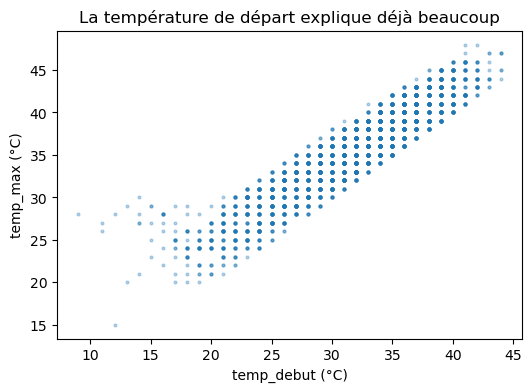

In [8]:
echantillon = sessions.sample(3000, random_state=RANDOM_STATE)
plt.figure(figsize=(6, 4))
plt.scatter(echantillon.temp_debut, echantillon.temp_max, s=4, alpha=0.3)
plt.xlabel("temp_debut (°C)")
plt.ylabel("temp_max (°C)")
plt.title("La température de départ explique déjà beaucoup")
plt.show()

---
## Étape 3 — Séparer train / test **par véhicule**

On entraîne sur **16 véhicules** et on teste sur **4 véhicules jamais vus** (17, 18, 19, 20).

**Pourquoi par véhicule ?** Si les sessions d'un même véhicule étaient à la fois dans le train et le test, le modèle pourrait « reconnaître » le véhicule au lieu d'apprendre une règle générale. Les résultats seraient trop optimistes, et ne vaudraient rien pour un nouveau véhicule de la flotte.

In [9]:
est_test = sessions["vehicle_id"].isin(TEST_VEHICLES)
train = sessions[~est_test]
test = sessions[est_test]

print(f"Train : {len(train):,} sessions — véhicules {sorted(train.vehicle_id.unique())}")
print(f"Test  : {len(test):,} sessions — véhicules {sorted(test.vehicle_id.unique())}")

Train : 24,673 sessions — véhicules [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16)]
Test  : 6,182 sessions — véhicules [np.int64(17), np.int64(18), np.int64(19), np.int64(20)]


Vérification : **aucun véhicule** n'est à la fois dans le train et le test.

In [10]:
commun = set(train.vehicle_id) & set(test.vehicle_id)
assert not commun, commun
print("OK : aucun véhicule en commun")

OK : aucun véhicule en commun


---
## Étape 4 — Définir les 3 algorithmes

| Algorithme | Principe | Rôle |
|---|---|---|
| **Régression linéaire** | une droite (somme pondérée des entrées) | **référence** : si un modèle complexe ne fait pas mieux, il est inutile |
| **Random Forest** | 200 arbres de décision, on fait la moyenne | capte les effets non linéaires, robuste |
| **XGBoost** | 300 petits arbres construits l'un après l'autre, chacun corrige les erreurs du précédent | souvent le plus précis sur des tableaux |

La régression linéaire a besoin de variables à la même échelle : on la précède d'un `StandardScaler`. Les arbres n'en ont pas besoin.

In [11]:
def creer_algorithmes():
    """Renvoie 3 modèles neufs (non entraînés)."""
    return {
        "lineaire": make_pipeline(StandardScaler(), LinearRegression()),
        "random_forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                               n_jobs=-1, random_state=RANDOM_STATE),
        "xgboost": XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05,
                                subsample=0.8, n_jobs=-1, random_state=RANDOM_STATE),
    }

creer_algorithmes()

{'lineaire': Pipeline(steps=[('standardscaler', StandardScaler()),
                 ('linearregression', LinearRegression())]),
 'random_forest': RandomForestRegressor(min_samples_leaf=5, n_estimators=200, n_jobs=-1,
                       random_state=42),
 'xgboost': XGBRegressor(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=-1, num_p

---
## Étape 5 — Définir les métriques

| Métrique | Signification | Idéal |
|---|---|---|
| **MAE** (erreur absolue moyenne) | en moyenne, de combien le modèle se trompe, dans l'unité de la cible (°C ou V) | proche de 0 |
| **RMSE** (racine de l'erreur quadratique moyenne) | comme la MAE, mais punit plus fort les grosses erreurs | proche de 0 |
| **R²** (coefficient de détermination) | part de la variation de la cible expliquée par le modèle | proche de 1 (0 = pas mieux que la moyenne) |

In [12]:
def metriques(y_reel, y_prevu):
    return {
        "MAE": mean_absolute_error(y_reel, y_prevu),
        "RMSE": float(np.sqrt(mean_squared_error(y_reel, y_prevu))),
        "R2": r2_score(y_reel, y_prevu),
    }

# Petit exemple : on se trompe de 1 °C sur chaque valeur
metriques([30, 35, 40], [31, 34, 41])

{'MAE': 1.0, 'RMSE': 1.0, 'R2': 0.94}

---
## Étape 6 — Un premier modèle, pas à pas

Avant de tout automatiser, on fait **un seul** entraînement à la main : régression linéaire sur `temp_max`.

**6.1 — Préparer X (entrées) et y (cible)** pour le train et le test :

In [13]:
X_train, y_train = train[FEATURES], train["temp_max"]
X_test, y_test = test[FEATURES], test["temp_max"]
print("X_train :", X_train.shape, "| X_test :", X_test.shape)

X_train : (24673, 5) | X_test : (6182, 5)


**6.2 — Entraîner** (`fit`) : le modèle apprend la relation entre conditions et température maximale, sur les 16 véhicules du train uniquement.

In [14]:
modele_lineaire = creer_algorithmes()["lineaire"]
modele_lineaire.fit(X_train, y_train)
print("Modèle entraîné")

Modèle entraîné


**6.3 — Lire les coefficients.** Comme les entrées sont standardisées, un coefficient indique de combien de °C varie `temp_max` quand la variable augmente d'un écart-type.

In [15]:
coefficients = pd.Series(modele_lineaire[-1].coef_, index=FEATURES).sort_values()
coefficients.round(2)

soc_debut       -1.33
courant_moyen   -0.82
mois             0.01
duree_min        0.14
temp_debut       5.06
dtype: float64

**6.4 — Prédire** (`predict`) la température maximale des sessions des 4 véhicules de test :

In [16]:
y_prevu = modele_lineaire.predict(X_test)
comparaison = pd.DataFrame({"temp_max réelle": y_test.values, "temp_max prévue": y_prevu.round(1)})
comparaison.head(10)

,temp_max réelle,temp_max prévue
0,40,41.2
1,43,41.7
2,44,42.5
3,40,41.7
4,40,39.9
5,41,39.8
6,40,40.5
7,39,39.1
8,39,39.1
9,36,36.6


**6.5 — Mesurer l'erreur** sur le test :

In [17]:
metriques(y_test, y_prevu)

{'MAE': 0.7333891215306191,
 'RMSE': 1.0509005400219011,
 'R2': 0.9628189677957871}

**Lecture.** Même une simple droite prédit la température maximale à moins de 1 °C près en moyenne (R² ≈ 0,96). Les modèles à arbres devront faire mieux pour être justifiés.

---
## Étape 7 — La validation croisée par véhicule

**Problème.** Pour **choisir** le meilleur algorithme et **fixer le seuil de vote**, on ne peut pas utiliser le test : il doit rester une mesure finale honnête.

**Solution : la validation croisée par véhicule (`GroupKFold`).** On découpe les 16 véhicules du train en 4 groupes. Tour à tour, on entraîne sur 3 groupes et on prédit le 4e. À la fin, **chaque session du train a une prédiction faite par un modèle qui n'a jamais vu son véhicule** : on parle de prédiction *hors-échantillon*.

Voici les 4 découpages :

In [18]:
plis = GroupKFold(n_splits=4)
for i, (idx_entr, idx_val) in enumerate(plis.split(train, groups=train["vehicle_id"]), 1):
    print(f"Pli {i} : validation sur les véhicules {sorted(train.vehicle_id.iloc[idx_val].unique())}")

Pli 1 : validation sur les véhicules [np.int64(2), np.int64(3), np.int64(8), np.int64(10)]
Pli 2 : validation sur les véhicules [np.int64(1), np.int64(11), np.int64(12), np.int64(13)]
Pli 3 : validation sur les véhicules [np.int64(4), np.int64(6), np.int64(7), np.int64(15)]
Pli 4 : validation sur les véhicules [np.int64(5), np.int64(9), np.int64(14), np.int64(16)]


Exemple sur la régression linéaire et `temp_max` : `cross_val_predict` renvoie une prédiction hors-échantillon pour chaque session du train.

In [19]:
oof_lineaire = cross_val_predict(creer_algorithmes()["lineaire"], X_train, y_train,
                                 groups=train["vehicle_id"], cv=plis)
print("Validation croisée :", {k: round(v, 4) for k, v in metriques(y_train, oof_lineaire).items()})
print("Test               :", {k: round(v, 4) for k, v in metriques(y_test, y_prevu).items()})

Validation croisée : {'MAE': 0.7278, 'RMSE': 1.0495, 'R2': 0.9633}
Test               : {'MAE': 0.7334, 'RMSE': 1.0509, 'R2': 0.9628}


**Lecture.** Les erreurs en validation croisée et sur le test sont presque identiques : la validation croisée est une bonne estimation de ce qui se passera sur de nouveaux véhicules. On peut donc s'y fier pour choisir le modèle.

---
## Étape 8 — Entraîner les 6 modèles

On répète les étapes 6 et 7 pour **2 cibles × 3 algorithmes = 6 modèles**. Pour chacun on garde :
- les prédictions hors-échantillon du train (pour choisir et fixer le seuil) ;
- le modèle entraîné sur tout le train ;
- ses prédictions sur le test (pour la mesure finale).

⏳ Cette cellule prend environ 1 minute.

In [20]:
oof = {}              # (cible, algorithme) -> prédictions hors-échantillon du train
modeles = {}          # (cible, algorithme) -> modèle entraîné sur tout le train
prevu_test = {}       # (cible, algorithme) -> prédictions sur le test
lignes = []

for anomalie, cible in CIBLES.items():
    for nom, modele in creer_algorithmes().items():
        # 1. Validation croisée par véhicule sur le train
        oof[(cible, nom)] = cross_val_predict(modele, train[FEATURES], train[cible],
                                              groups=train["vehicle_id"], cv=plis)
        # 2. Entraînement sur tout le train
        modele.fit(train[FEATURES], train[cible])
        modeles[(cible, nom)] = modele
        # 3. Prédiction sur les 4 véhicules de test
        prevu_test[(cible, nom)] = modele.predict(test[FEATURES])

        m_cv = metriques(train[cible], oof[(cible, nom)])
        m_test = metriques(test[cible], prevu_test[(cible, nom)])
        lignes.append({"cible": cible, "algorithme": nom,
                       "MAE cv": m_cv["MAE"], "MAE test": m_test["MAE"],
                       "RMSE test": m_test["RMSE"], "R² test": m_test["R2"]})
        print(f"✔ {cible:<12} {nom}")

✔ temp_max     lineaire


✔ temp_max     random_forest


✔ temp_max     xgboost
✔ ecart_v_max  lineaire


✔ ecart_v_max  random_forest


✔ ecart_v_max  xgboost


---
## Étape 9 — Comparer et choisir le meilleur

Le meilleur modèle est celui qui a la **plus petite MAE en validation croisée** (pas sur le test).

In [21]:
resultats = pd.DataFrame(lignes)
resultats["meilleur"] = resultats.groupby("cible")["MAE cv"].transform("min") == resultats["MAE cv"]
resultats

,cible,algorithme,MAE cv,MAE test,RMSE test,R² test,meilleur
0,temp_max,lineaire,0.7278,0.7334,1.0509,0.9628,False
1,temp_max,random_forest,0.5611,0.5617,0.7650,0.9803,False
2,temp_max,xgboost,0.5163,0.5233,0.6959,0.9837,True
3,ecart_v_max,lineaire,0.0050,0.0052,0.0067,0.2288,False
4,ecart_v_max,random_forest,0.0049,0.0049,0.0063,0.3074,False
5,ecart_v_max,xgboost,0.0048,0.0049,0.0064,0.2991,True


Même comparaison en graphique (MAE en °C pour `temp_max`, en mV pour `ecart_v_max`) :

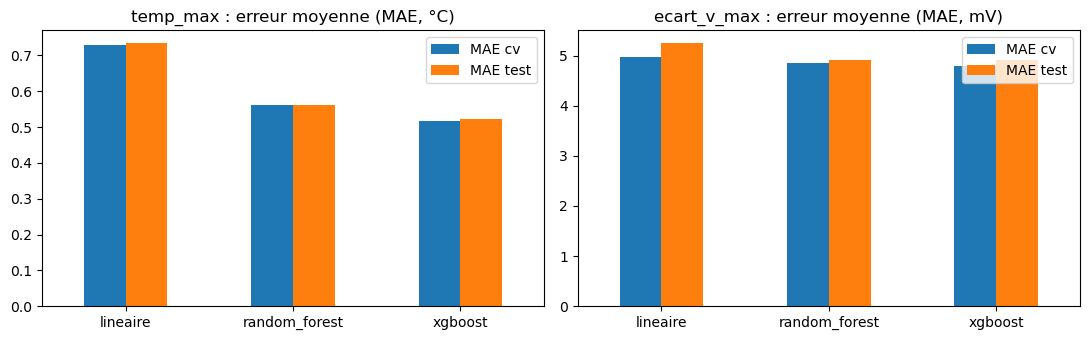

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, cible in zip(axes, CIBLES.values()):
    r = resultats[resultats.cible == cible].set_index("algorithme")
    unite, facteur = ("°C", 1) if cible == "temp_max" else ("mV", 1000)
    (r[["MAE cv", "MAE test"]] * facteur).plot.bar(ax=ax, rot=0)
    ax.set_title(f"{cible} : erreur moyenne (MAE, {unite})")
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "regression_comparaison_mae.png", dpi=120)
plt.show()

In [23]:
meilleurs = resultats[resultats.meilleur].set_index("cible")["algorithme"].to_dict()
meilleurs

{'temp_max': 'xgboost', 'ecart_v_max': 'xgboost'}

**Lecture.**
- **XGBoost** est le meilleur pour les deux cibles, devant Random Forest puis la régression linéaire.
- Pour `temp_max`, il réduit l'erreur d'environ 30 % par rapport à la droite (≈ 0,52 °C contre 0,73 °C).
- Pour `ecart_v_max`, les 3 algorithmes sont proches et le R² reste faible (≈ 0,3) : les conditions de charge expliquent mal l'écart de tension.

---
## Étape 10 — Prévu contre réel (véhicules de test)

Chaque point est une session de test. S'il est sur la diagonale rouge, la prédiction est parfaite. Les points **au-dessus** de la diagonale sont des sessions **plus chaudes (ou plus déséquilibrées) que prévu** : ce sont elles qui nous intéressent.

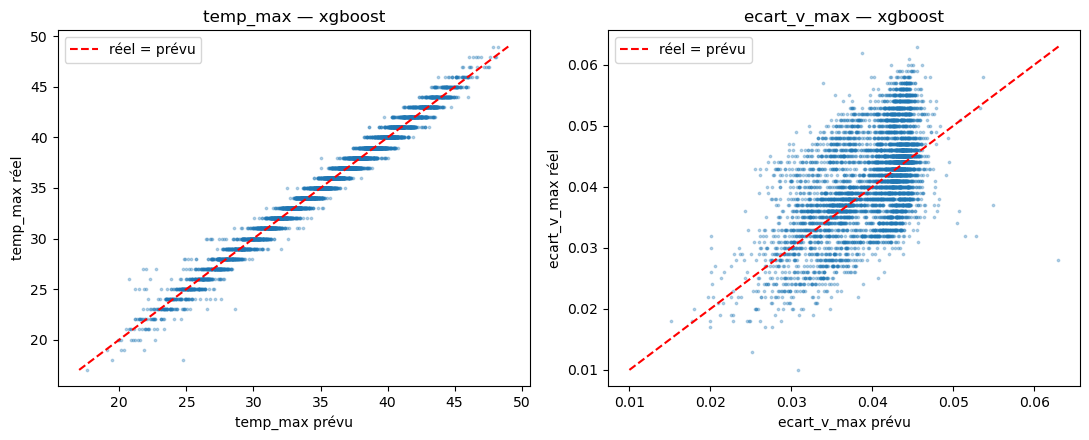

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, cible in zip(axes, CIBLES.values()):
    prevu = prevu_test[(cible, meilleurs[cible])]
    ax.scatter(prevu, test[cible], s=3, alpha=0.3)
    bornes = [min(prevu.min(), test[cible].min()), max(prevu.max(), test[cible].max())]
    ax.plot(bornes, bornes, "r--", label="réel = prévu")
    ax.set_xlabel(f"{cible} prévu")
    ax.set_ylabel(f"{cible} réel")
    ax.set_title(f"{cible} — {meilleurs[cible]}")
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "regression_prevu_vs_reel.png", dpi=120)
plt.show()

**Lecture.**
- **`temp_max`** : les points suivent bien la diagonale.
- **`ecart_v_max`** : le nuage est large. L'écart de tension dépend surtout de **l'état de la batterie elle-même**, pas des conditions de charge — et c'est justement ce qui rend un écart anormal intéressant.

---
## Étape 11 — Fixer le seuil de vote

Le **résidu** d'une session est **réel − prévu** :
- résidu ≈ 0 → la session se comporte comme prévu ;
- résidu **grand et positif** → plus chaude (ou plus déséquilibrée) que prévu → **suspecte**.

**Règle choisie :** une session vote « anomalie » si son résidu dépasse le **99e percentile** des résidus du train. Autrement dit, elle fait partie du 1 % des sessions les plus au-dessus du prévu.

On utilise les résidus **hors-échantillon** (étape 7). Sur ses propres données d'entraînement, une forêt « connaît » déjà les réponses : ses résidus y seraient trop petits, et le seuil trop bas.

In [25]:
PERCENTILE_VOTE = 99
seuils = {}
residus_train = {}
for anomalie, cible in CIBLES.items():
    residus_train[anomalie] = train[cible] - oof[(cible, meilleurs[cible])]
    seuils[anomalie] = float(np.percentile(residus_train[anomalie], PERCENTILE_VOTE))

print(f"Surchauffe : vote si temp_max dépasse le prévu de plus de {seuils['surchauffe']:.2f} °C")
print(f"Cellule    : vote si ecart_v_max dépasse le prévu de plus de {seuils['cellule'] * 1000:.1f} mV")

Surchauffe : vote si temp_max dépasse le prévu de plus de 1.63 °C
Cellule    : vote si ecart_v_max dépasse le prévu de plus de 16.1 mV


Distribution des résidus et position du seuil (échelle logarithmique, pour voir les rares grands résidus) :

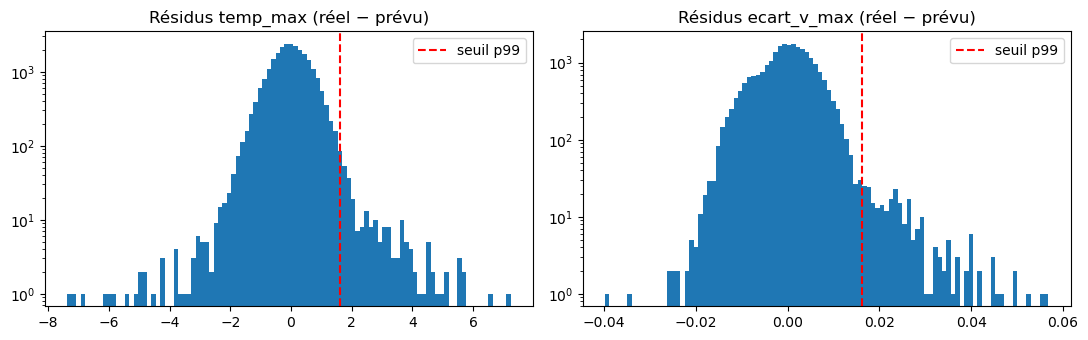

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (anomalie, cible) in zip(axes, CIBLES.items()):
    ax.hist(residus_train[anomalie], bins=100)
    ax.axvline(seuils[anomalie], color="r", linestyle="--", label=f"seuil p{PERCENTILE_VOTE}")
    ax.set_yscale("log")
    ax.set_title(f"Résidus {cible} (réel − prévu)")
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "regression_residus.png", dpi=120)
plt.show()

---
## Étape 12 — Voter sur toutes les sessions

Pour chaque session (train et test) et chaque anomalie :
1. on prédit la valeur attendue avec le meilleur modèle ;
2. on calcule le résidu ;
3. on vote 1 si le résidu dépasse le seuil, sinon 0.

On produit **un vote par anomalie** (option D : fusion par anomalie) et `vote_regression` = 1 si l'un des deux vote (compatible avec la fusion actuelle).

In [27]:
votes = sessions[["vehicle_id", "session_id"]].copy()

for anomalie, cible in CIBLES.items():
    meilleur_modele = modeles[(cible, meilleurs[cible])]
    votes[f"{cible}_prevu"] = meilleur_modele.predict(sessions[FEATURES])
    votes[f"residu_{cible}"] = sessions[cible].to_numpy() - votes[f"{cible}_prevu"]
    votes[f"vote_regression_{anomalie}"] = (votes[f"residu_{cible}"] > seuils[anomalie]).astype(int)

votes["vote_regression"] = votes[["vote_regression_surchauffe", "vote_regression_cellule"]].max(axis=1)
votes.head()

,vehicle_id,session_id,temp_max_prevu,residu_temp_max,vote_regression_surchauffe,ecart_v_max_prevu,residu_ecart_v_max,vote_regression_cellule,vote_regression
0,1,1,43.7570,0.2430,0,0.0359,-0.0109,0,0
1,1,2,43.0227,-0.0227,0,0.0372,-0.0072,0,0
2,1,3,38.3964,1.6036,0,0.0380,-0.0080,0,0
3,1,4,38.0990,1.9010,1,0.0278,-0.0048,0,1
4,1,5,37.3225,-0.3225,0,0.0306,-0.0086,0,0


Part des sessions qui votent « anomalie », sur le train et sur le test :

In [28]:
est_test_votes = votes.vehicle_id.isin(TEST_VEHICLES)
pd.DataFrame({
    "train": votes.loc[~est_test_votes, ["vote_regression_surchauffe", "vote_regression_cellule", "vote_regression"]].mean(),
    "test": votes.loc[est_test_votes, ["vote_regression_surchauffe", "vote_regression_cellule", "vote_regression"]].mean(),
}).style.format("{:.2%}")

,train,test
vote_regression_surchauffe,0.65%,1.07%
vote_regression_cellule,0.73%,0.39%
vote_regression,1.38%,1.44%


**Lecture.** Environ 1 % des sessions votent « surchauffe », comme attendu avec le 99e percentile. Le taux est proche entre train et test : le seuil se transpose bien à de nouveaux véhicules.

---
## Étape 13 — Analyser les votes

**13.1 — Quels véhicules sont signalés ?**

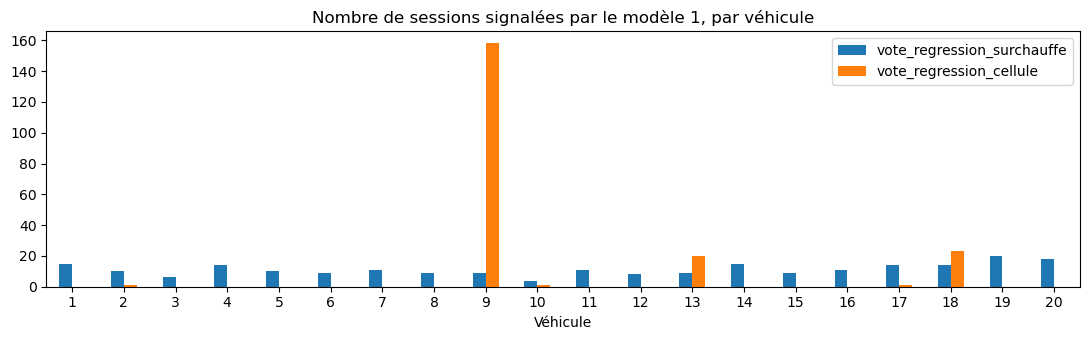

vehicle_id,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
vote_regression_surchauffe,15,10,6,14,10,9,11,9,9,4,11,8,9,15,9,11,14,14,20,18
vote_regression_cellule,0,1,0,0,0,0,0,0,158,1,0,0,20,0,0,0,1,23,0,0


In [29]:
par_vehicule = votes.groupby("vehicle_id")[["vote_regression_surchauffe", "vote_regression_cellule"]].sum()
ax = par_vehicule.plot.bar(figsize=(11, 3.5), rot=0)
ax.set_title("Nombre de sessions signalées par le modèle 1, par véhicule")
ax.set_xlabel("Véhicule")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "regression_votes_par_vehicule.png", dpi=120)
plt.show()
par_vehicule.T

**Lecture.**
- **Surchauffe** : les votes sont répartis sur **tous** les véhicules. Ce sont des sessions ponctuellement plus chaudes que prévu, pas un véhicule défectueux.
- **Cellule** : les votes se concentrent sur le **véhicule 9** (puis 18 et 13). Ce sont les mêmes véhicules que ceux trouvés par le seuil de 60 mV : **deux approches indépendantes désignent le même véhicule**.

**13.2 — Les 10 sessions les plus « plus chaudes que prévu »**

In [30]:
exemples = (votes.merge(sessions[["session_id", "debut", "courant_moyen", "temp_debut", "temp_max"]], on="session_id")
              .sort_values("residu_temp_max", ascending=False)
              .head(10))
exemples[["vehicle_id", "debut", "courant_moyen", "temp_debut", "temp_max", "temp_max_prevu", "residu_temp_max"]].round(2)

,vehicle_id,debut,courant_moyen,temp_debut,temp_max,temp_max_prevu,residu_temp_max
27140,18,2020-12-17 06:39:20,-51.23,17,26,20.70,5.30
24082,16,2021-01-08 07:06:47,-47.42,18,28,22.74,5.26
28711,19,2021-01-09 11:47:10,-66.26,19,27,21.76,5.24
30314,20,2021-01-12 03:21:18,-68.91,19,27,21.96,5.04
5823,4,2021-01-09 07:01:31,-39.83,18,27,22.18,4.82
18034,12,2020-12-17 02:36:08,-51.77,18,29,24.49,4.51
27189,18,2021-01-11 11:35:56,-45.03,11,27,22.76,4.24
13655,9,2021-01-08 01:19:52,-64.42,19,27,22.85,4.15
18106,12,2021-01-19 07:00:19,-57.78,18,29,24.87,4.13
5775,4,2020-12-15 11:51:43,-47.05,17,26,22.06,3.94


**13.3 — Le modèle 1 trouve-t-il des sessions que les seuils fixes ne voient pas ?**

On compare le vote « surchauffe » du modèle 1 avec le seuil fixe `temp_max > 45 °C`.

In [31]:
seuil_fixe = (sessions["temp_max"] > 45).astype(int).to_numpy()
pd.crosstab(pd.Series(seuil_fixe, name="seuil > 45 °C"),
            pd.Series(votes["vote_regression_surchauffe"].to_numpy(), name="vote modèle 1"))

vote modèle 1,0,1
seuil > 45 °C,,
0,30335,217
1,294,9


**Lecture.** Les deux approches se recoupent très peu (9 sessions en commun) :
- **217 sessions** sont signalées par le **modèle 1 seul** : elles restent sous 45 °C, mais sont anormalement chaudes pour leurs conditions. C'est **l'apport propre du modèle 1**.
- **294 sessions** dépassent 45 °C sans être signalées par le modèle 1 : elles sont chaudes, mais **normalement** chaudes vu leurs conditions (départ déjà chaud, été, fort courant).

Les deux approches voient donc des choses différentes : c'est exactement pourquoi on les combine dans le vote.

---
## Étape 14 — Importance des variables

Quelles conditions comptent le plus pour le meilleur modèle (XGBoost) ?

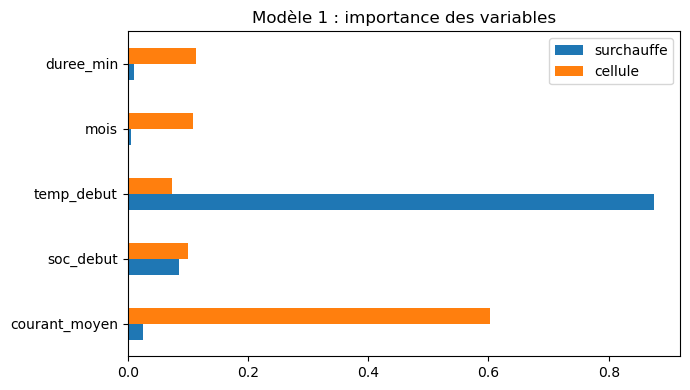

,surchauffe,cellule
courant_moyen,0.025,0.602
soc_debut,0.085,0.101
temp_debut,0.875,0.074
mois,0.005,0.109
duree_min,0.010,0.114


In [32]:
importance = pd.DataFrame(
    {anomalie: modeles[(cible, meilleurs[cible])].feature_importances_ for anomalie, cible in CIBLES.items()},
    index=FEATURES)
ax = importance.plot.barh(figsize=(7, 4))
ax.set_title("Modèle 1 : importance des variables")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "regression_importance.png", dpi=120)
plt.show()
importance.round(3)

**Lecture.**
- **Surchauffe** : la **température de départ** domine largement. Le modèle apprend la montée normale de température et signale ce qui dépasse.
- **Cellule** : le **courant** est la variable principale : une charge plus forte creuse l'écart entre cellules.

---
## Étape 15 — Sauvegarder les votes

Le fichier `data/processed/votes_regression.parquet` est lu par **Mohamed** pour la fusion par vote. Colonnes : `vote_regression_surchauffe`, `vote_regression_cellule`, `vote_regression`, plus les valeurs prévues et les résidus (utiles au dashboard pour expliquer une alerte).

In [33]:
chemin_votes = PROCESSED_DIR / "votes_regression.parquet"
votes.to_parquet(chemin_votes, index=False)
print("Votes enregistrés :", chemin_votes)
print(votes.shape)

Votes enregistrés : C:\Users\hp\Documents\HESTIM 2\PROJET PISTE\battery-charging-data-of-on-road-electric-vehicles-main\Dataset_automobile\data\processed\votes_regression.parquet
(30855, 9)


---
## Étape 16 — Conclusions

| | Surchauffe (`temp_max`) | Cellule (`ecart_v_max`) |
|---|---|---|
| Meilleur modèle | XGBoost | XGBoost |
| Précision (test) | MAE ≈ 0,5 °C, R² ≈ 0,98 | MAE ≈ 5 mV, R² ≈ 0,3 |
| Seuil de vote | ≈ 1,6 °C au-dessus du prévu | ≈ 16 mV au-dessus du prévu |
| Sessions signalées | ≈ 1 % | ≈ 0,5 % |
| Ce qu'on apprend | Les conditions expliquent presque toute la température : un écart au prévu est un vrai signal | Les conditions expliquent mal l'écart de tension : il vient de l'état de la batterie |
| Véhicules signalés | Répartis sur toute la flotte | Surtout le **véhicule 9** (puis 18 et 13) |

**Apport du modèle 1 :** il repère des sessions **anormales pour leurs conditions**, même sous les seuils fixes, et confirme par une approche indépendante le cas du véhicule 9.

**Limites :**
- La température est enregistrée au degré près : une erreur de 0,5 °C est proche de la précision du capteur.
- Le seuil (99e percentile) signale par construction environ 1 % des sessions : c'est un choix, à confronter aux autres votes dans la fusion.
- `duree_min` n'est connue qu'à la fin de la session : ce modèle analyse une session **terminée**. L'anticipation est le rôle du modèle 2 (alerte précoce).